# **Customer Analysis**

In [1]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [3]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

In [4]:
def currency_formatter(x, _):
    if x >= 1_000_000_000:
        val = x / 1e9
        return f'${val:.1f}B'.replace('.0B', 'B')
    elif x >= 1_000_000:
        val = x / 1e6
        return f'${val:.1f}M'.replace('.0M', 'M')
    elif x >= 1_000:
        val = x / 1e3
        return f'${val:.1f}K'.replace('.0K', 'K')
    else:
        return f'${x:,.0f}'

## 1. Load Only Relevant Columns

In [5]:
CUSTOMER_COLUMNS = [
    # Year
    'order_year',
    
    # CUSTOMER PROFILE
    'customer_name',
    'gender',
    'age',
    'age_group',
    'customer_segment',
    'country',

    # PURCHASE BEHAVIOR
    'quantity',
    'net_revenue_usd',
    'profit_usd',
    'order_value_segment',

    # LOYALTY
    'customer_loyalty_score',
    'loyalty_tier',

    # ENGAGEMENT
    'session_duration_min',
    'engagement_level',
    'pages_visited',

    # CUSTOMER JOURNEY
    'abandoned_cart_before',
    'coupon_used',

    # DEVICE / ACQUISITION
    'device_type',
    'traffic_source',
]

In [6]:
customer_df = ecommerce_df[CUSTOMER_COLUMNS].copy()

In [17]:
customer_df.sample(10)

,order_year,customer_name,gender,age,age_group,customer_segment,country,quantity,net_revenue_usd,profit_usd,order_value_segment,customer_loyalty_score,loyalty_tier,session_duration_min,engagement_level,pages_visited,abandoned_cart_before,coupon_used,device_type,traffic_source
619266,2024,Brittany Chavez,Female,46,45-54,Regular,Belgium,1,47.28,11.18,Low,4.80,Low,48.50,High,2,No,No,Desktop,Email
767335,2024,Harold Young,Male,60,55-64,Regular,United Kingdom,4,483.98,159.38,High,85.20,High,24.90,Medium,11,No,No,Mobile,Social
767785,2024,Jeffrey Garcia DDS,Male,19,18-24,Regular,Canada,4,106.77,19.21,Medium,60.60,Medium,55.10,High,4,No,No,Mobile,Social
694140,2024,Brenda Williams,Female,44,35-44,Regular,Belgium,2,234.80,101.46,Medium,89.80,High,35.30,Medium,4,No,Yes,Mobile,Referral
586501,2025,Marc Graves,Male,48,45-54,Regular,Germany,5,171.94,23.49,Medium,87.90,High,12.70,Low,1,Yes,Yes,Desktop,Referral
418875,2025,Joseph Garcia,Male,41,35-44,Regular,United States,3,250.14,93.63,Medium,39.80,Medium,26.80,Medium,13,Yes,No,Tablet,Social
100849,2024,Brooke Vasquez,Female,19,18-24,Regular,Canada,1,84.74,35.59,Low,68.90,Medium,40.90,High,3,No,Yes,Tablet,Email
110817,2024,Justin Smith,Male,59,55-64,Regular,France,3,155.88,64.89,Medium,3.90,Low,24.10,Medium,16,Yes,No,Tablet,Email
200809,2024,Juan Harrison,Male,47,45-54,Regular,Germany,1,59.49,6.91,Low,9.50,Low,8.60,Low,17,Yes,No,Mobile,Direct
652963,2025,Melinda May,Female,62,55-64,Regular,Canada,1,296.27,110.23,Medium,65.70,Medium,24.70,Medium,9,No,Yes,Desktop,Referral


## 2. Customer Overview

In [7]:
print(f"Total Transactions      :   {customer_df.shape[0]:,}")
print(f"Countries Covered       :   {customer_df['country'].nunique()}")
print(f"Customer Segments       :   {customer_df['customer_segment'].nunique()}")
print(f"Average Age             :   {customer_df['age'].mean():.2f}")
print(f"Average Loyalty         :   {customer_df['customer_loyalty_score'].mean():.2f}")

Total Transactions      :   1,000,123
Countries Covered       :   10
Customer Segments       :   3
Average Age             :   46.49
Average Loyalty         :   49.97


## 3. Customer Demographics

### 3.1 Customer Age Distribution

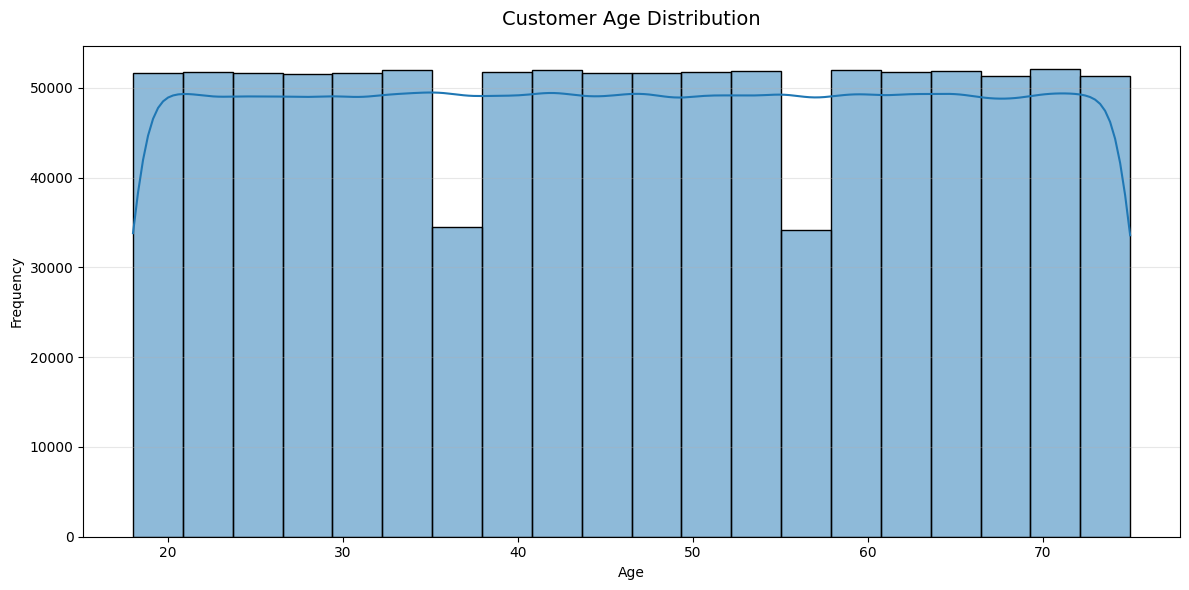

In [8]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(
    data=customer_df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Customer Age Distribution', fontsize=14, pad=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Average Transaction Value by Age Group

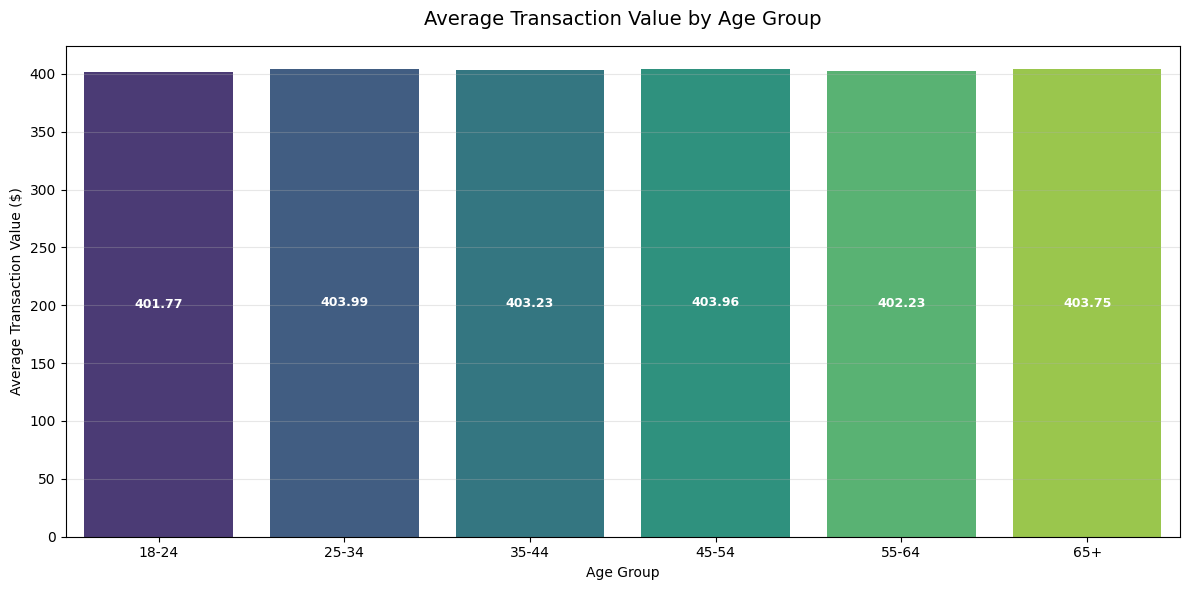

In [9]:
age_value = (
    customer_df
    .groupby('age_group', observed=True)
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=age_value,
    x='age_group',
    y='avg_transaction_value',
    palette='viridis',
    hue='age_group',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Age Group', fontsize=14, pad=15)
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Value ($)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Customer Transactions by Gender Across Year

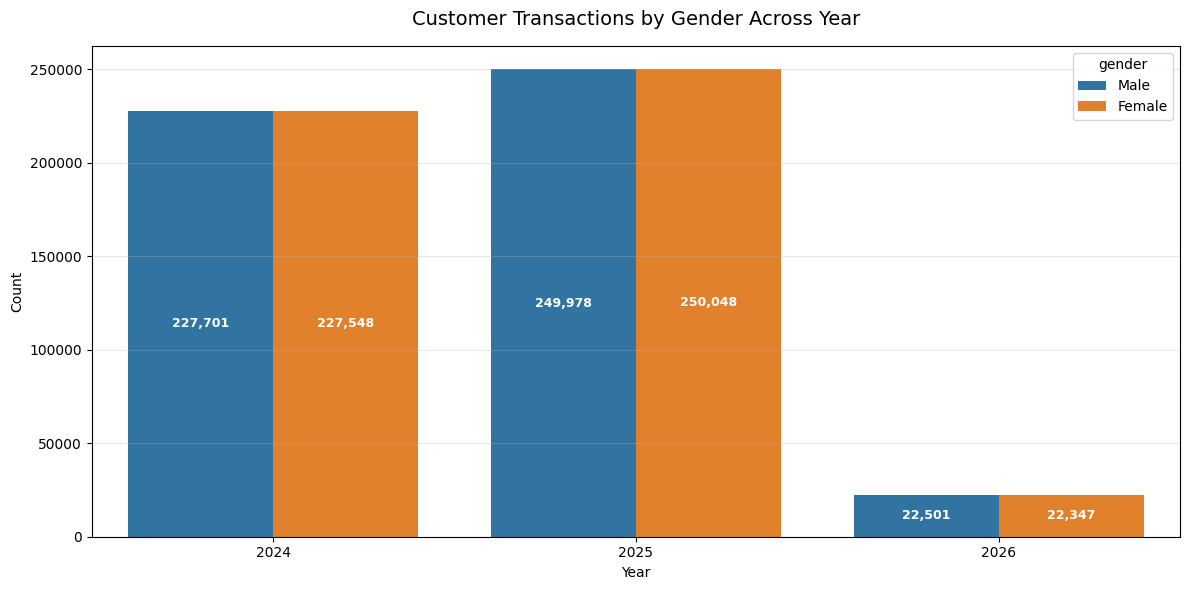

In [16]:
transaction_gender = (
    customer_df
    .groupby('order_year')['gender']
    .value_counts()
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=transaction_gender,
    x='order_year',
    y='count',
    hue='gender'
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Customer Transactions by Gender Across Year', fontsize=14, pad=15)
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Customer Segment Analysis

### 4.1 Average Transaction Value by Customer Segment Across Year

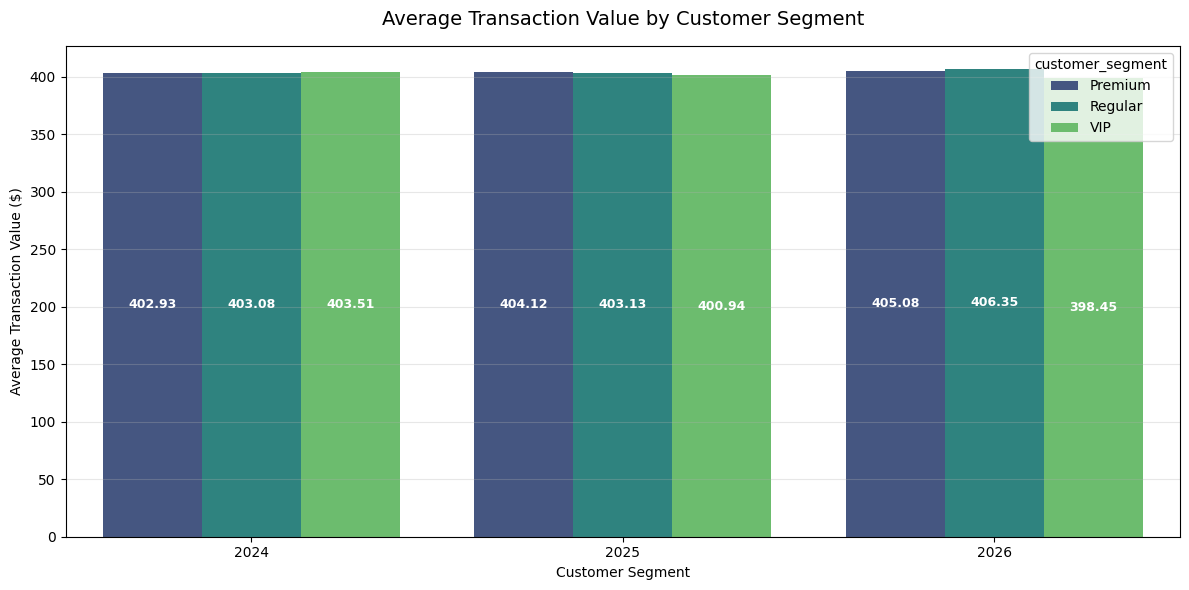

In [20]:
customer_value = (
    customer_df
    .groupby(['order_year', 'customer_segment'])
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=customer_value,
    x='order_year',
    y='avg_transaction_value',
    palette='viridis',
    hue='customer_segment',
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Customer Segment', fontsize=14, pad=15)
plt.xlabel('Customer Segment')
plt.ylabel('Average Transaction Value ($)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Customer Loyalty

### 5.1 Loyalty Tier Distribution

### 5.2 Loyalty Score vss Transaction Value

## 6. Customer Engagement

### 6.1 Engagement Level Distribution

### 6.2 Purchase Quantity vs Transaction Value

## 7. Purchase Behavior

### 7.1 Previous Cart Abandonment

### 7.2 Transaction Value by Cart Abandonment

## 8. Customer Acquisition

### 8.1 Average Transaction Value by Traffic Source

## 9. Customer Value Matrix

### 9.1 Customer Segment x Order Value Segment